# Experiments

Runs the comparisons of the study and an Optuna hyperparameter search. Training and testing
live in `src/runner.py`.

1. **Comparisons**: DTNet vs the feedforward baseline, mixed vs single generator, loops in
   training, and zero-init. Each run writes to `results/<name>/` and `checkpoints/<name>.pt`.
   Finished runs are loaded instead of re-run, and partial runs only evaluate the missing
   test sets, so the notebook can be re-run or resumed cheaply.
2. **Optuna search** on short proxy runs, scored on held-out larger mazes from the *training*
   generators, so the test generators are never used for tuning.
3. **Retrain the best configuration** at full length and run the full test.

Set the environment variable `MAZE_QUICK=1` for a fast end-to-end check (meaningless numbers,
written to `results/quick/`).

## Setup

In [1]:
import os
import subprocess
import sys
from dataclasses import replace
from pathlib import Path

REPO_URL = "https://github.com/yoshi0428/maze-generalization.git"
BRANCH = "main"

if "google.colab" in sys.modules:
    root = Path("/content/maze-generalization")
    if root.is_dir():
        subprocess.run(["git", "-C", str(root), "pull", "--ff-only"], check=True)
    else:
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(root)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna"], check=True)
else:
    root = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

# Lets the size-63 curriculum (batch 4 x 150 iterations) fit in 16 GB; must be set before torch.
os.environ.setdefault("PYTORCH_ALLOC_CONF", "expandable_segments:True")

sys.path.insert(0, str(root / "src"))

import matplotlib.pyplot as plt
import optuna
import pandas as pd
import torch
from tqdm.auto import tqdm

from runner import Config, plot_history, plot_results, run, run_or_load

QUICK = os.environ.get("MAZE_QUICK") == "1"
RESULTS = root / "results" / ("quick" if QUICK else "")
CHECKPOINTS = root / "checkpoints" / ("quick" if QUICK else "")
print("device:", torch.cuda.get_device_name() if torch.cuda.is_available() else "cpu", " quick:", QUICK)

device: NVIDIA GeForce RTX 5060 Ti  quick: False


## 1. Comparisons

All runs share `BASE`: train on size-15 mazes from DFS, Prim's and Kruskal's for 20 epochs, test
on the unseen generators at sizes 15 to 511. Larger test mazes get fewer samples because each
one takes up to 3000 iterations (about 20 ms per iteration at 511). Tests with walls removed
stop at size 127 (`loop_test_max_size`). A full run takes ~17 min to train and ~1 h to test
on an RTX 5060 Ti.

In [2]:
BASE = Config(
    name="base",
    train_generators=("dfs", "prim", "kruskal"),
    train_size=15, n_train=30_000, epochs=20, batch=64, lr=1e-3, warmup=2,
    alpha=0.01, max_iters=30, clip=2.0,
    # size -> (number of test mazes, eval batch size)
    test_sizes={15: (250, 100), 31: (250, 100), 63: (200, 50), 127: (100, 25), 255: (40, 8), 511: (16, 2)},
    test_wr=(0.0, 0.1),
    test_iters=(30, 100, 300, 1000, 3000),
)

EXPERIMENTS = [
    replace(BASE, name="dtnet_s15_noloops"),                                  # reference
    replace(BASE, name="ff_s15_noloops", model="ff", depth=30, alpha=0.0,     # fixed-depth baseline
            test_iters=(1,)),
    replace(BASE, name="dtnet_s15_dfs", train_generators=("dfs",)),           # single generator
    replace(BASE, name="dtnet_s15_loops", train_wr=(0.0, 0.1), lr=3e-4),     # loops in training (lr 1e-3 is unstable with loops)
    replace(BASE, name="dtnet_s15_noloops_zeroinit", zero_init=True),         # zero-init blocks
]

if QUICK:
    small = dict(n_train=600, epochs=2, width=32, max_iters=10, warmup=0,
                 test_sizes={15: (20, 10), 31: (20, 10)}, test_iters=(10, 30))
    EXPERIMENTS = [replace(c, **{**small, **({"depth": 4, "test_iters": (1,)} if c.model == "ff" else {})})
                   for c in EXPERIMENTS]

In [3]:
runs = {}
for cfg in tqdm(EXPERIMENTS, desc="experiments"):
    runs[cfg.name] = run_or_load(cfg, RESULTS, CHECKPOINTS, progress=True, log=tqdm.write)
    if runs[cfg.name].get("cached"):
        tqdm.write(f"{cfg.name}: loaded from {RESULTS / cfg.name}")

experiments: 100%|██████████| 5/5 [00:00<00:00, 707.35it/s]

dtnet_s15_noloops: loaded from /home/yoshi0428/PycharmProjects/maze-generalization/results/dtnet_s15_noloops
ff_s15_noloops: loaded from /home/yoshi0428/PycharmProjects/maze-generalization/results/ff_s15_noloops
dtnet_s15_dfs: loaded from /home/yoshi0428/PycharmProjects/maze-generalization/results/dtnet_s15_dfs
dtnet_s15_loops: loaded from /home/yoshi0428/PycharmProjects/maze-generalization/results/dtnet_s15_loops
dtnet_s15_noloops_zeroinit: loaded from /home/yoshi0428/PycharmProjects/maze-generalization/results/dtnet_s15_noloops_zeroinit


### Results

Fraction of test mazes solved, taking the best iteration count for each model (DTNet can
run more iterations on larger mazes; the feedforward baseline has a fixed depth).

In [4]:
def best_over_iters(r):
    return max(r.values())


rows = []
for cfg in EXPERIMENTS:
    res = runs[cfg.name]["results"]
    for key, r in res.items():
        if key.startswith("extrap"):
            continue
        wr, size = key.split("/")
        rows.append({"run": cfg.name, "wall removal": float(wr), "size": int(size),
                     "solved": best_over_iters(r)})

table = pd.DataFrame(rows).pivot_table(index=["wall removal", "run"], columns="size", values="solved")
table.style.format("{:.1%}", na_rep="-").background_gradient(cmap="Greens", vmin=0, vmax=1)

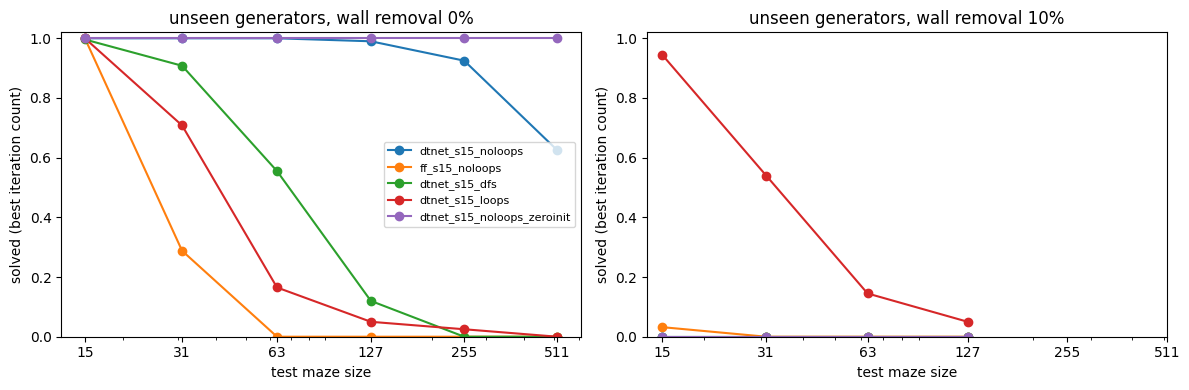

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, wr in zip(axes, BASE.test_wr):
    for cfg in EXPERIMENTS:
        res = runs[cfg.name]["results"]
        sizes = [s for s in cfg.test_sizes if f"{wr}/{s}" in res]
        ax.plot(sizes, [best_over_iters(res[f"{wr}/{s}"]) for s in sizes], marker="o", label=cfg.name)

    ax.set(xscale="log", xticks=list(BASE.test_sizes), xticklabels=list(BASE.test_sizes),
           xlabel="test maze size", ylabel="solved (best iteration count)", ylim=(0, 1.02),
           title=f"unseen generators, wall removal {wr:.0%}")

axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

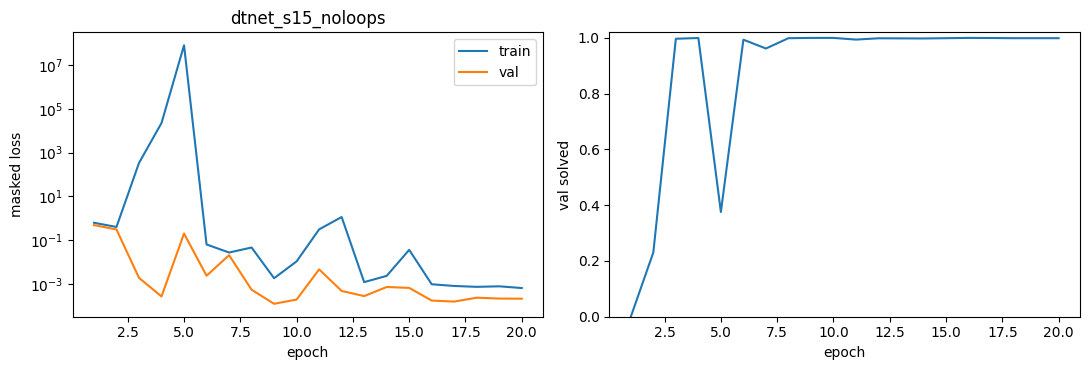

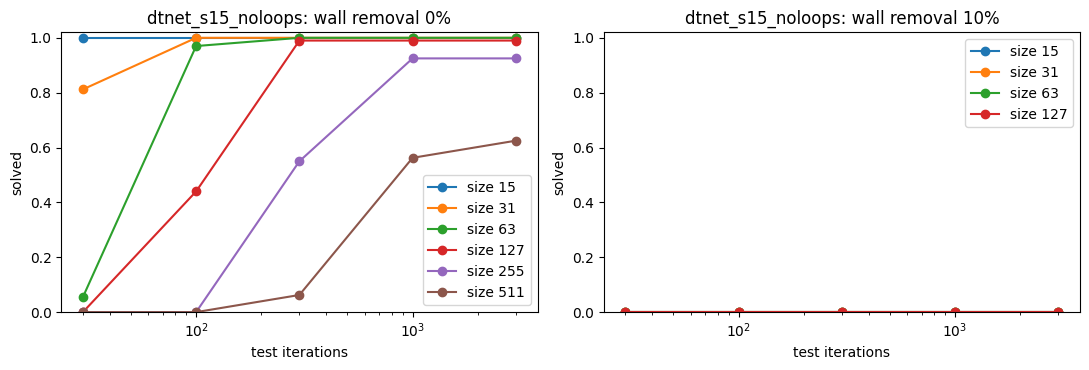

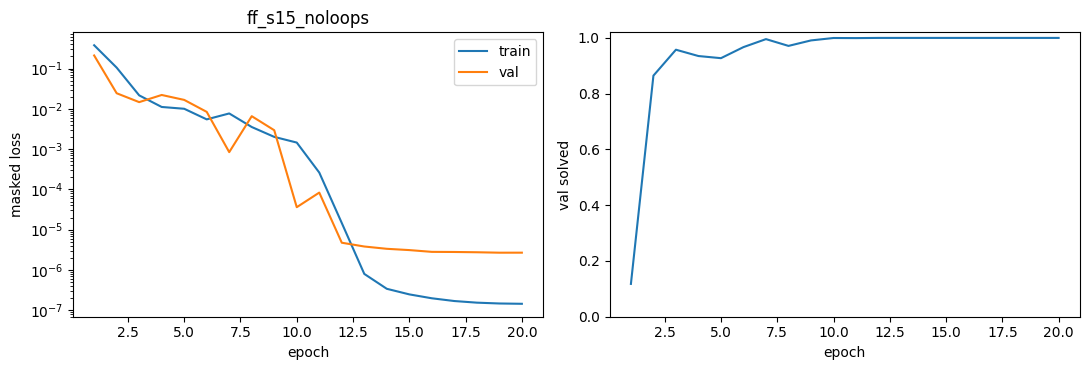

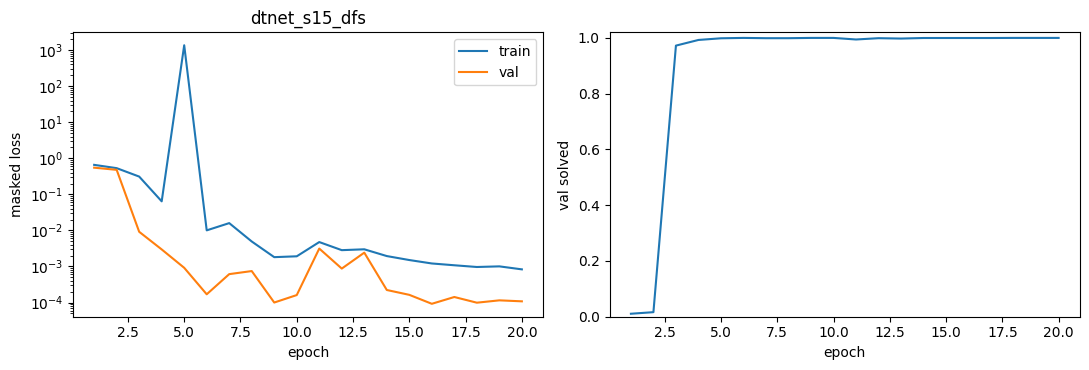

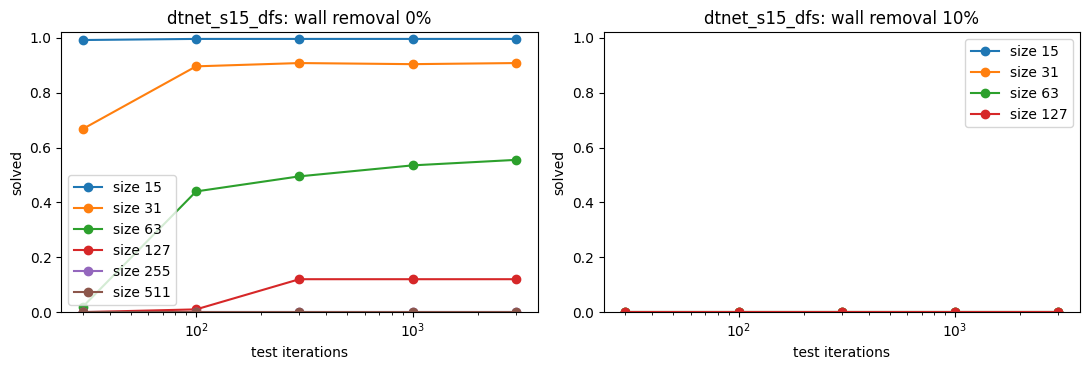

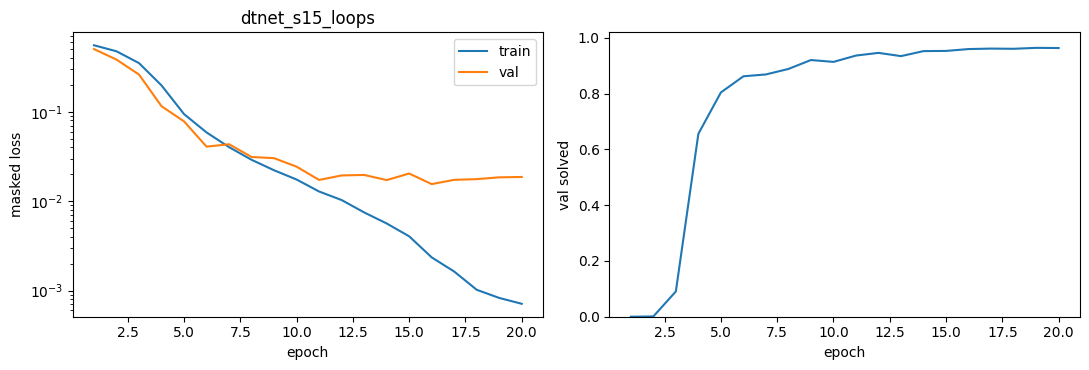

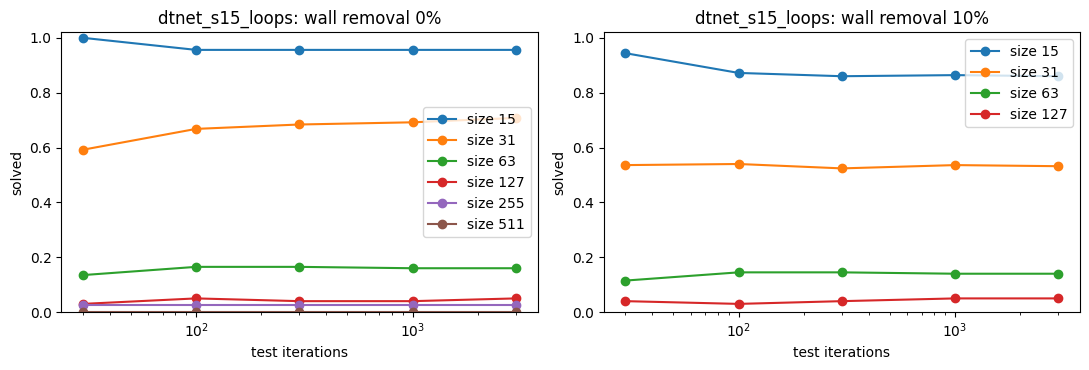

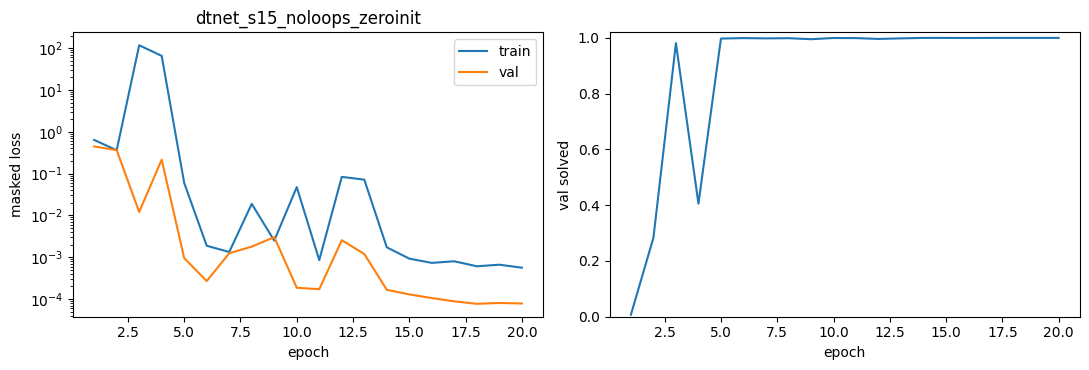

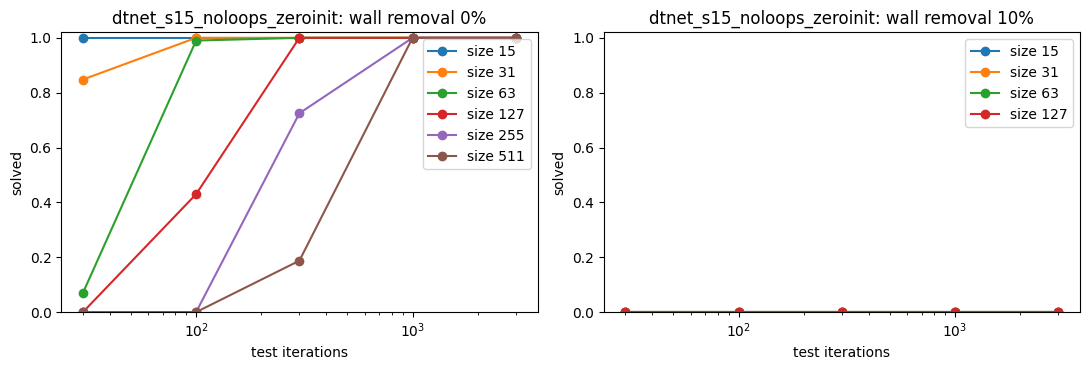

In [6]:
# Training curves and solved-vs-iterations plots of every run.
for cfg in EXPERIMENTS:
    if runs[cfg.name]["history"]:
        plot_history(runs[cfg.name]["history"], cfg)
        plt.show()
    if cfg.model != "ff":
        plot_results(runs[cfg.name]["results"], cfg)
        plt.show()

## 2. Optuna hyperparameter search

Each trial trains a short proxy run (10k mazes, 8 epochs, ~2.5 min per seed on an RTX 5060 Ti)
and is scored on 100 held-out size-63 mazes from the **training** generators at 300 iterations
(`extrap/63`). Scoring at a fixed, large iteration count penalises overthinking.

Results vary a lot between seeds (39–93% for identical settings in earlier sweeps), so each
trial averages `SEEDS_PER_TRIAL` seeds, and every trial uses the same seeds so that trials are
compared on the same data. Trials that have not learned by epoch 4 (validation far below the
median of earlier trials) are pruned.

The study is stored in `results/optuna/dtnet.db`, so an interrupted search resumes where it
stopped when this cell is run again. Budget: `N_TRIALS` x `SEEDS_PER_TRIAL` x ~2.5 min
(40 x 2 = ~3.5 h), less with pruning.

In [9]:
N_TRIALS = 10
SEEDS_PER_TRIAL = 2
STUDY_NAME = "dtnet_proxy"

PROXY = replace(
    BASE, n_train=10_000, epochs=8, warmup=1, test_sizes={},
    extrap_sizes={31: (100, 100), 63: (100, 50)}, test_iters=(100, 300),
)
SCORE_KEY, SCORE_ITERS = "extrap/63", 300


def suggest(trial):
    """Search space. Ranges are centred on the settings that worked in earlier runs."""
    return dict(
        lr=trial.suggest_float("lr", 5e-4, 3e-3, log=True),
        alpha=trial.suggest_float("alpha", 3e-3, 0.3, log=True),
        clip=trial.suggest_float("clip", 0.25, 4.0, log=True),
        max_iters=trial.suggest_int("max_iters", 15, 45, step=5),
        width=trial.suggest_categorical("width", [64, 128]),
        zero_init=trial.suggest_categorical("zero_init", [False, True]),
    )


if QUICK:
    N_TRIALS, SEEDS_PER_TRIAL, STUDY_NAME = 3, 1, "quick"
    PROXY = replace(PROXY, n_train=300, epochs=2, warmup=0, extrap_sizes={31: (10, 10)},
                    test_iters=(10,))
    SCORE_KEY, SCORE_ITERS = "extrap/31", 10
    _suggest = suggest
    suggest = lambda trial: {**_suggest(trial), "width": 16, "max_iters": 5}

In [ ]:
def objective(trial):

    params = suggest(trial)
    scores = []

    for seed in range(SEEDS_PER_TRIAL):
        cfg = replace(PROXY, name=f"trial{trial.number}_s{seed}", seed=seed, **params)

        def report(epoch, history, seed=seed):
            if seed == 0:  # prune on the first seed's validation curve
                trial.report(history["val_solved"][-1], epoch)
                if trial.should_prune():
                    raise optuna.TrialPruned()

        out = run(cfg, on_epoch=report, log=lambda msg: None)  # nothing written to disk
        scores.append(out["results"][SCORE_KEY][SCORE_ITERS])
        trial.set_user_attr(f"seed{seed}", scores[-1])
        trial.set_user_attr(f"seed{seed}_extrap31", out["results"]["extrap/31"][max(PROXY.test_iters)])

    return sum(scores) / len(scores)


(RESULTS / "optuna").mkdir(parents=True, exist_ok=True)

study = optuna.create_study(
    study_name=STUDY_NAME,
    storage=f"sqlite:///{RESULTS / 'optuna' / 'dtnet.db'}",
    load_if_exists=True,
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=0),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=4),
)

optuna.logging.set_verbosity(optuna.logging.WARNING)

remaining = N_TRIALS - len([t for t in study.trials if t.state.is_finished()])

if remaining > 0:
    study.optimize(objective, n_trials=remaining, show_progress_bar=True)

print(f"{len(study.trials)} trials, best score {study.best_value:.1%}: {study.best_params}")

Best trial: 0. Best value: 0.855:  20%|██        | 2/10 [10:10<40:34, 304.27s/it]

In [7]:
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state", "duration"))
trials.sort_values("value", ascending=False).head(15)

NameError: name 'study' is not defined

<positron-console-cell-11>:3: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.


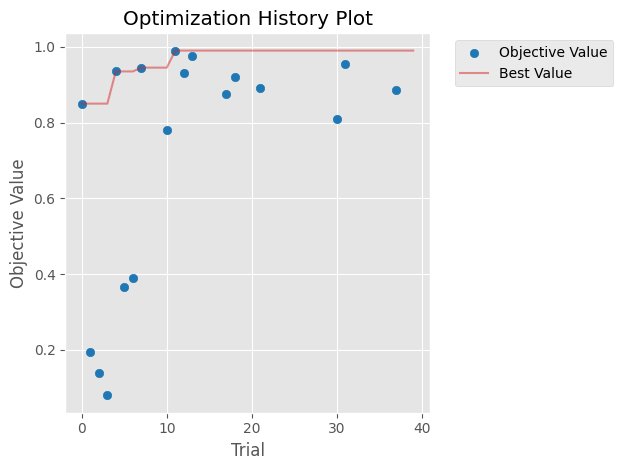

<positron-console-cell-11>:7: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.


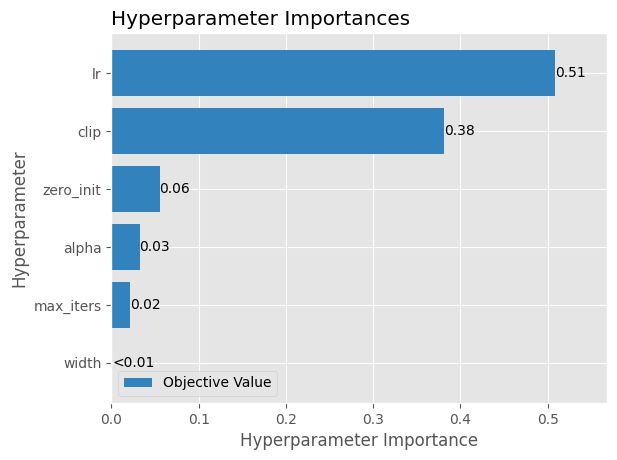

<positron-console-cell-11>:9: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.


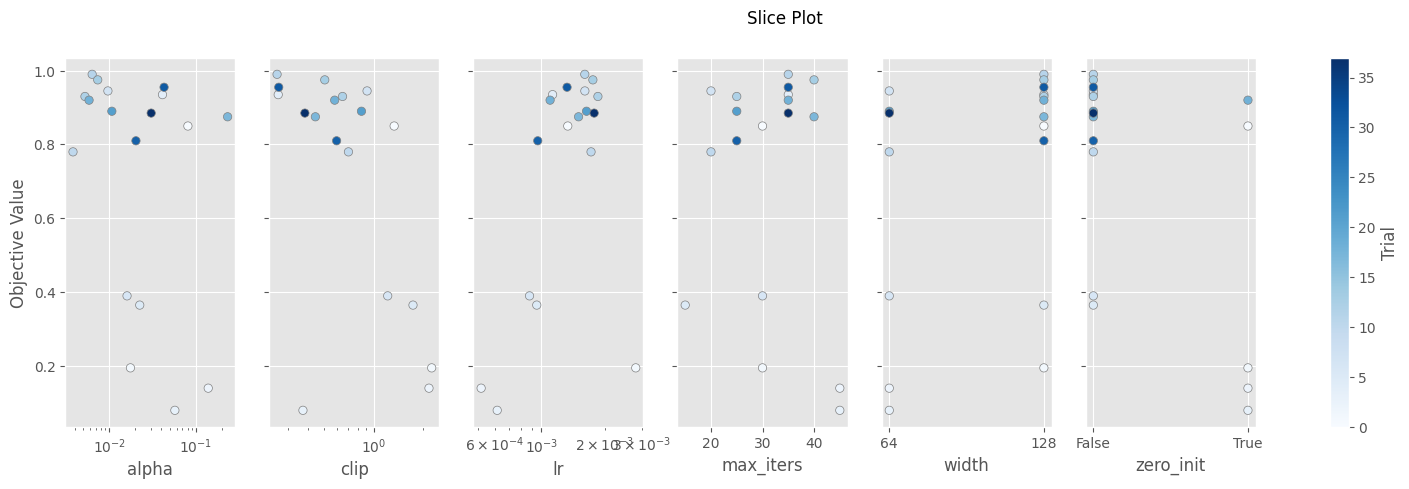

In [11]:
from optuna.visualization import matplotlib as ovis

ovis.plot_optimization_history(study)
plt.show()

if len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]) >= 5:
    ovis.plot_param_importances(study)
    plt.show()
    ovis.plot_slice(study)
    plt.show()

## 3. Retrain the best configuration

Proxy scores are noisy, so the best trial is retrained at full length with the `BASE` data and
the full test, and compared with the reference run in the table above.

In [12]:
best_cfg = replace(BASE, name="dtnet_optuna_best" if not QUICK else "quick_best", **study.best_params)

if QUICK:
    best_cfg = replace(best_cfg, **small)

print(best_cfg)

runs[best_cfg.name] = run_or_load(best_cfg, RESULTS, CHECKPOINTS, progress=True, log=tqdm.write)

ref = EXPERIMENTS[0]
for name in (ref.name, best_cfg.name):
    res = runs[name]["results"]
    print(f"{name:28s}", "  ".join(
        f"{s}: {best_over_iters(res[f'0.0/{s}']):.1%}" for s in BASE.test_sizes if f"0.0/{s}" in res
    ))

Config(name='dtnet_optuna_best', model='dtnet', width=128, depth=30, zero_init=False, train_generators=('dfs', 'prim', 'kruskal'), train_size=15, n_train=30000, train_wr=0.0, val_fraction=0.1, epochs=20, batch=64, lr=0.0016100291375377848, warmup=2, alpha=0.006332871181957377, max_iters=35, clip=0.25921044890136113, test_generators=('eller', 'wilson', 'hunt_and_kill', 'recursive_division', 'sidewinder'), test_sizes={15: (250, 100), 31: (250, 100), 63: (200, 50), 127: (100, 25), 255: (40, 8), 511: (16, 2)}, test_wr=(0.0, 0.1), loop_test_max_size=127, test_iters=(30, 100, 300, 1000, 3000), extrap_sizes={}, amp=True, init_from=None, seed=0)
== dtnet_optuna_best: dtnet, 783,504 params


data: 27000 train / 3000 val, size 15


KeyboardInterrupt: 